# Week 2 - Preprocessing, part 2

# 1. Lesson: None

# 2. Weekly graph question

The Storytelling With Data book mentions planning on a "Who, What, and How" for your data story.  Write down a possible Who, What, and How for your data, using the ideas in the book.

**Who:** Medicare and insurers, who focus on controlling costs and reducing unnecessary utilization. Secondary audiences are providers and patients.

**What:** Poorly managed diabetes leads to repeated hospital encounters. Readmissions are a measurable indicator of inefficiencies in care delivery and a key driver of cost for patients, providers, and insurers.

**How:** Use the Diabetes 130-US Hospitals dataset (100k+ encounters) to show which patient characteristics and prior utilization patterns are associated with 30-day readmission, such as readmission rates by number of prior inpatient visits, to help identify high-risk patients for earlier intervention.

*Note: Builds on the framing from my group's Milestone Two submission in a previous semester*


# 3. Homework - work with your chosen project datasets this semester

In [6]:
import pandas as pd
import numpy as np
from datetime import datetime, timedelta

This week, you will do the same types of exercises as last week, but you should use your chosen datasets that someone in your class found last semester. (They likely will not be the particular datasets that you found yourself.)

### Here are some types of analysis you can do  Use Google, documentation, and ChatGPT to help you:

- Summarize the datasets using info() and describe()

- Are there any duplicate rows?

- Are there any duplicate values in a given column (when this would be inappropriate?)

- What are the mean, median, and mode of each column?

- Are there any missing or null values?

    - Do you want to fill in the missing value with a mean value?  A value of your choice?  Remove that row?

- Identify any other inconsistent data (e.g. someone seems to be taking an action before they are born.)

- Encode any categorical variables (e.g. with one-hot encoding.)

### Conclusions:

- Are the data usable?  If not, find some new data!

- Do you need to modify or correct the data in some way?

- Is there any class imbalance?  (Categories that have many more items than other categories).

   **Dataset:** Diabetes 130-US Hospitals (1999–2008), UCI Machine Learning Repository
   https://archive.ics.uci.edu/dataset/296/diabetes+130-us+hospitals+for+years+1999-2008
   
   **File used**: diabetic_data.csv

In [7]:
df = pd.read_csv('diabetic_data.csv')
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      101766 non-null  object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    101766 non-null  object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                101766 non-null  object
 11  medical_specialty         101766 non-null  object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-null  int64 
 14  num_

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [8]:
df.describe()

,encounter_id,patient_nbr,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,1.017660e+05,1.017660e+05,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000
mean,1.652016e+08,5.433040e+07,2.024006,3.715642,5.754437,4.395987,43.095641,1.339730,16.021844,0.369357,0.197836,0.635566,7.422607
std,1.026403e+08,3.869636e+07,1.445403,5.280166,4.064081,2.985108,19.674362,1.705807,8.127566,1.267265,0.930472,1.262863,1.933600
min,1.252200e+04,1.350000e+02,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000
25%,8.496119e+07,2.341322e+07,1.000000,1.000000,1.000000,2.000000,31.000000,0.000000,10.000000,0.000000,0.000000,0.000000,6.000000
50%,1.523890e+08,4.550514e+07,1.000000,1.000000,7.000000,4.000000,44.000000,1.000000,15.000000,0.000000,0.000000,0.000000,8.000000
75%,2.302709e+08,8.754595e+07,3.000000,4.000000,7.000000,6.000000,57.000000,2.000000,20.000000,0.000000,0.000000,1.000000,9.000000
max,4.438672e+08,1.895026e+08,8.000000,28.000000,25.000000,14.000000,132.000000,6.000000,81.000000,42.000000,76.000000,21.000000,16.000000


101,766 rows and 50 columns. 13 columns are numeric and 37 are text.

In [9]:
df.dtypes

encounter_id                 int64
patient_nbr                  int64
race                        object
gender                      object
age                         object
weight                      object
admission_type_id            int64
discharge_disposition_id     int64
admission_source_id          int64
time_in_hospital             int64
payer_code                  object
medical_specialty           object
num_lab_procedures           int64
num_procedures               int64
num_medications              int64
number_outpatient            int64
number_emergency             int64
number_inpatient             int64
diag_1                      object
diag_2                      object
diag_3                      object
number_diagnoses             int64
max_glu_serum               object
A1Cresult                   object
metformin                   object
repaglinide                 object
nateglinide                 object
chlorpropamide              object
glimepiride         

In [10]:
id_cols = ['admission_type_id', 'discharge_disposition_id', 'admission_source_id']
df[id_cols] = df[id_cols].astype(str)

admission_type_id, discharge_disposition_id and admission_source_id are stored as numbers, but they're really category codes, so I changin them to text makes sense here. encounter_id and patient_nbr are IDs too and shouldn't be averaged.

In [11]:
df = df.replace('?', np.nan)
missing = df.isnull().sum()
missing[missing > 0]

race                  2273
weight               98569
payer_code           40256
medical_specialty    49949
diag_1                  21
diag_2                 358
diag_3                1423
max_glu_serum        96420
A1Cresult            84748
dtype: int64

In [12]:
df = df.drop(columns=['weight', 'payer_code', 'medical_specialty'])
df['race'] = df['race'].fillna('Unknown')

before = len(df)
df = df.dropna(subset=['diag_1', 'diag_2', 'diag_3'])
print("Rows dropped for missing diagnosis:", before - len(df))

df['max_glu_serum'] = df['max_glu_serum'].fillna('Not tested')
df['A1Cresult'] = df['A1Cresult'].fillna('Not tested')

Rows dropped for missing diagnosis: 1522


Missing values were stored as "?". Weight (~97% missing), payer_code and medical_specialty (~40–50%) were dropped. race was filled with "Unknown". Rows missing a diagnosis were dropped (see the printed count). Blank max_glu_serum and A1Cresult mean the test wasn't done, so they were filled with "Not tested".

In [13]:
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()

Duplicate rows: 0


In [14]:
print(df['encounter_id'].is_unique)

True


In [15]:
print("Unique patients:", df['patient_nbr'].nunique())
print("Total rows:", len(df))

Unique patients: 70416
Total rows: 100244


~70,000 unique patients across ~100k visits, so many patients show up more than once. That's expected because readmissions are repeat visits. Visits from the same patient aren't independent which could matter for modeling.

In [16]:
num_cols = ['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications',
            'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']
print("Mean:\n", df[num_cols].mean().round(1))
print("\nMedian:\n", df[num_cols].median())
print("\nMode:\n", df[num_cols].mode().iloc[0])
print("\nMax:\n", df[num_cols].max())

Mean:
 time_in_hospital       4.4
num_lab_procedures    43.2
num_procedures         1.4
num_medications       16.1
number_outpatient      0.4
number_emergency       0.2
number_inpatient       0.6
number_diagnoses       7.5
dtype: float64

Median:
 time_in_hospital       4.0
num_lab_procedures    44.0
num_procedures         1.0
num_medications       15.0
number_outpatient      0.0
number_emergency       0.0
number_inpatient       0.0
number_diagnoses       8.0
dtype: float64

Mode:
 time_in_hospital       3
num_lab_procedures     1
num_procedures         0
num_medications       13
number_outpatient      0
number_emergency       0
number_inpatient       0
number_diagnoses       9
Name: 0, dtype: int64

Max:
 time_in_hospital       14
num_lab_procedures    132
num_procedures          6
num_medications        81
number_outpatient      42
number_emergency       76
number_inpatient       21
number_diagnoses       16
dtype: int64


Most columns look normal. The exception is number_emergency and number_outpatient: most patients have 0 visits, but a few have a lot (up to 76 and 42).

In [17]:
print(df['gender'].value_counts())
df = df[df['gender'] != 'Unknown/Invalid']

gender
Female             53922
Male               46319
Unknown/Invalid        3
Name: count, dtype: int64


In [18]:
# 11, 19, 20, 21 = patient expired
expired = df['discharge_disposition_id'].isin(['11', '19', '20', '21'])
print("Expired patients:", expired.sum())
df = df[~expired]

Expired patients: 1650


3 rows with gender "Unknown/Invalid" were removed. 1,650 visits ended with the patient dying. Those patients can't be readmitted, so those rows were removed.

In [19]:
df_encoded = pd.get_dummies(df, columns=['gender', 'A1Cresult'])
df_encoded.head()

,encounter_id,patient_nbr,race,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,...,metformin-pioglitazone,change,diabetesMed,readmitted,gender_Female,gender_Male,A1Cresult_>7,A1Cresult_>8,A1Cresult_Norm,A1Cresult_Not tested
1,149190,55629189,Caucasian,[10-20),1,1,7,3,59,0,...,No,Ch,Yes,>30,True,False,False,False,False,True
2,64410,86047875,AfricanAmerican,[20-30),1,1,7,2,11,5,...,No,No,Yes,NO,True,False,False,False,False,True
3,500364,82442376,Caucasian,[30-40),1,1,7,2,44,1,...,No,Ch,Yes,NO,False,True,False,False,False,True
4,16680,42519267,Caucasian,[40-50),1,1,7,1,51,0,...,No,Ch,Yes,NO,False,True,False,False,False,True
5,35754,82637451,Caucasian,[50-60),2,1,2,3,31,6,...,No,No,Yes,>30,False,True,False,False,False,True


gender and A1Cresult are now 0/1 columns. Invalid gender rows and expired patients are already removed.

### Conclusions

In [20]:
print("Final rows:", len(df))
df['readmitted'].value_counts(normalize=True).round(2)

Final rows: 98591


readmitted
NO     0.53
>30    0.36
<30    0.11
Name: proportion, dtype: float64

### Conclusions
- **Usable?** Yes. After cleaning there are 98,591 visits, no duplicate rows, and encounter_id is unique.
- **Fixes needed:** "?" had to be treated as missing, 3 mostly empty columns were dropped, ID codes were changed to categories, and rows with a missing diagnosis, an invalid gender, or an expired patient were removed.
- **Imbalance:** Yes. readmitted is about 53% NO, 36% > 30, and only 11% < 30. The < 30 group is the most important one to predict, and it's the smallest.

# 4. Storytelling With Data graph

Just like last week: choose any graph in the Introduction of Storytelling With Data (p. 1-17). Use matplotlib to reproduce it in a rough way. I don't expect you to spend an enormous amount of time on this; I understand that you likely will not have time to re-create every feature of the graph. However, if you're excited about learning to use matplotlib, this is a good way to do that. You don't have to duplicate the exact values on the graph; just the same rough shape will be enough.  If you don't feel comfortable using matplotlib yet, do the best you can and write down what you tried or what Google searches you did to find the answers.

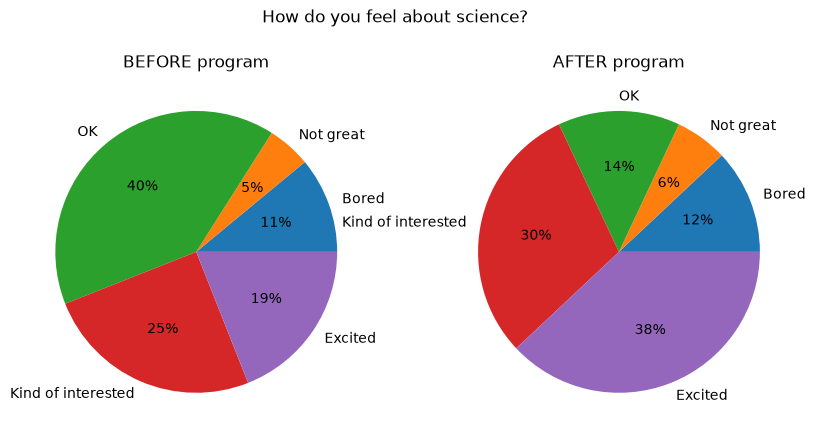

In [21]:
import matplotlib.pyplot as plt

labels = ['Bored', 'Not great', 'OK', 'Kind of interested', 'Excited']
before = [11, 5, 40, 25, 19]
after = [12, 6, 14, 30, 38]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

ax1.pie(before, labels=labels, autopct='%1.0f%%')
ax1.set_title('BEFORE program')

ax2.pie(after, labels=labels, autopct='%1.0f%%')
ax2.set_title('AFTER program')

fig.suptitle('How do you feel about science?')
plt.show()


I orughly  recreated the before and after pie charts from Storytelling With Data. They show that fewer kids felt OK about science and more felt Excited after the program. As the book mentions, it is hard to compare two pie charts side by side, which is why redrawing the data as a bar chart gives a clearer picture of the pre and post program results.